In [ ]:
import os.path as op
import pandas as pd
import numpy as np
from scipy.stats import zscore
import statsmodels.api as sm
import statsmodels.formula.api as smf

results_path = '../../results_DPZ'
df_final = pd.read_csv(op.join(results_path, 'df_combined_final_cha_DPZ.csv'))
specificity_df = pd.read_csv(op.join(results_path, 'hemi_specificity.csv'))

groups = ['DPZ', 'PL']

In [ ]:
#### DEFINE ROIS

# === 1. Clean specificity_df ===
specificity_df_clean = specificity_df.copy()
specificity_df_clean['ch_name_clean'] = (
    specificity_df_clean['ch_name']
    .str.strip()
    .str.lower()
    .str.replace(' hbo', '', regex=False)
)

# === 2. Prepare beta records ===
groups = df_final['group'].unique()
conditions = ['A']
chromas = ['hbo']
records = []

for chroma in chromas:
    for condition in conditions:
        df_condition = df_final.query(f"Chroma == '{chroma}' and Condition == '{condition}'").copy()
        df_condition['day'] = df_condition['day'].astype(float)
        df_condition['subject'] = df_condition['subject'].astype(str)

        for group in groups:
            df_group = df_condition[df_condition['group'] == group]
            for subject in df_group['subject'].unique():
                df_subject = df_group[df_group['subject'] == subject]
                df_day1 = df_subject[df_subject['day'] == 1.0].set_index('ch_name')['theta']
                df_day3 = df_subject[df_subject['day'] == 3.0].set_index('ch_name')['theta']

                common_channels = df_day1.index.intersection(df_day3.index)
                for ch in common_channels:
                    ch_clean = ch.strip().lower().replace(" hbo", "").replace(" hbdiff", "")
                    records.append({
                        'group': group,
                        'subject': subject,
                        'condition': condition,
                        'chroma': chroma,
                        'channel_clean': ch_clean,
                        'beta': df_day1.loc[ch],
                        'day': 1.0
                    })
                    records.append({
                        'group': group,
                        'subject': subject,
                        'condition': condition,
                        'chroma': chroma,
                        'channel_clean': ch_clean,
                        'beta': df_day3.loc[ch],
                        'day': 3.0
                    })

df_beta_long = pd.DataFrame(records)

# === 3. Merge with filtered specificity info ===
df_merged = df_beta_long.merge(
    specificity_df_clean[['ch_name_clean', 'Landmark', 'Hemisphere', 'Specificity']],
    left_on='channel_clean',
    right_on='ch_name_clean',
    how='inner'
)

# === 4. Assign ROIs ===
def classify_roi(landmark):
    if not isinstance(landmark, str):
        return None
    landmark_lower = landmark.lower()

    # === Visual cortex landmarks ===
    if any(k in landmark_lower for k in [
        "v1", "v2", "v3", 
        "fusiform gyrus", "inferior temporal gyrus", "middle temporal gyrus"
    ]):
        return "Occipital"

    # === Auditory / temporal landmarks ===
    elif any(k in landmark_lower for k in [
        "superior temporal gyrus", 
        "auditory", "a1", "a2",
        "angular gyrus",
        "supramarginal gyrus", 
        "temporopolar area"
    ]):
        return "Temporal"

    # === Frontal landmarks ===
    elif any(k in landmark_lower for k in [
        "pars triangularis", 
        "pars opercularis",
        "dorsolateral prefrontal cortex", "dlpfc",
        "motor cortex", "pre-motor", "supplementary motor", "premotor",
        "frontal eye fields"
    ]):
        return "Frontal"

    # No ROI match
    return None

df_merged['ROI'] = df_merged['Landmark'].apply(classify_roi)
df_merged = df_merged[df_merged['ROI'].notna()]

df_merged['ROI_hemi'] = df_merged['ROI'] + ' (' + df_merged['Hemisphere'].astype(str) + ')'
channel_to_roihemi = (
    df_merged[['channel_clean', 'ROI_hemi']]
    .dropna()
    .groupby('channel_clean', as_index=False)
    .agg(ROI_hemi=('ROI_hemi', lambda s: s.mode().iat[0]))
)

# === 5. Z-score theta per subject × chroma
df_merged['z_beta'] = df_merged.groupby(['subject', 'chroma', 'day'])['beta'].transform(zscore)
df_test = df_merged.copy()

In [ ]:
# === 1. Run ANOVA per ROI × Hemisphere
import statsmodels.api as sm

for ROI_hemi in df_test['ROI_hemi'].unique():
   roi_df = df_test[df_test['ROI_hemi'] == ROI_hemi]
   print(f"\nANOVA for {ROI_hemi}):")
   roi_df['subject'] = roi_df['subject'].astype(str)   # avoid pandas Int64Dtype
   roi_df['group']   = roi_df['group'].astype(str)     # ensure categorical
   roi_df['day']     = roi_df['day'].astype(str)       # ensure categorical

   model = smf.mixedlm("z_beta ~ C(group) * C(day)",
                     data=roi_df,
                     groups=roi_df["subject"])
   result = model.fit()
   print(result.summary())
else:
      print(f"No {ROI_hemi} ROI found after thresholding.")




ANOVA for Frontal (Right)):
                 Mixed Linear Model Regression Results
Model:                  MixedLM      Dependent Variable:      z_beta   
No. Observations:       496          Method:                  REML     
No. Groups:             8            Scale:                   0.6873   
Min. group size:        62           Log-Likelihood:          -619.5530
Max. group size:        62           Converged:               Yes      
Mean group size:        62.0                                           
-----------------------------------------------------------------------
                             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------------------
Intercept                    -0.043    0.116 -0.368 0.713 -0.270  0.185
C(group)[T.PL]                0.076    0.164  0.465 0.642 -0.245  0.398
C(day)[T.3.0]                -0.196    0.105 -1.863 0.062 -0.403  0.010
C(group)[T.PL]:C(day)[T.3.0] -0.016    0.149 -0.109 

/var/folders/dv/s4k5_3r51ml3q36bgbcdsgbr0000gn/T/ipykernel_82773/2291030636.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  roi_df['subject'] = roi_df['subject'].astype(str)   # avoid pandas Int64Dtype
/var/folders/dv/s4k5_3r51ml3q36bgbcdsgbr0000gn/T/ipykernel_82773/2291030636.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  roi_df['group']   = roi_df['group'].astype(str)     # ensure categorical
/var/folders/dv/s4k5_3r51ml3q36bgbcdsgbr0000gn/T/ipykernel_82773/2291030636.py:9: SettingWithCopyWarning:

                 Mixed Linear Model Regression Results
Model:                  MixedLM      Dependent Variable:      z_beta   
No. Observations:       368          Method:                  REML     
No. Groups:             8            Scale:                   0.9733   
Min. group size:        46           Log-Likelihood:          -522.6335
Max. group size:        46           Converged:               Yes      
Mean group size:        46.0                                           
-----------------------------------------------------------------------
                             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------------------
Intercept                     0.131    0.125  1.048 0.294 -0.114  0.376
C(group)[T.PL]               -0.198    0.177 -1.120 0.263 -0.545  0.149
C(day)[T.3.0]                -0.403    0.145 -2.773 0.006 -0.688 -0.118
C(group)[T.PL]:C(day)[T.3.0]  0.316    0.206  1.536 0.125 -0.087  0.719
Group Var

/var/folders/dv/s4k5_3r51ml3q36bgbcdsgbr0000gn/T/ipykernel_82773/2291030636.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  roi_df['subject'] = roi_df['subject'].astype(str)   # avoid pandas Int64Dtype
/var/folders/dv/s4k5_3r51ml3q36bgbcdsgbr0000gn/T/ipykernel_82773/2291030636.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  roi_df['group']   = roi_df['group'].astype(str)     # ensure categorical
/var/folders/dv/s4k5_3r51ml3q36bgbcdsgbr0000gn/T/ipykernel_82773/2291030636.py:9: SettingWithCopyWarning:

LinAlgError: Singular matrix

In [18]:
# === 2. Run paired t-test within subjects
import scipy.stats as stats
import pandas as pd
import statsmodels.formula.api as smf

df_test['day'] = pd.to_numeric(df_test['day'], errors='coerce').astype('Int64')

for roi_name in ['Temporal', 'Occipital', 'Frontal']:
    roi_df = df_test[df_test['ROI'] == roi_name]
    if roi_df.empty:
        print(f"No {roi_name} ROI found after thresholding.")
        continue

    for hemi in roi_df['Hemisphere'].dropna().unique():
        hemi_df = roi_df[roi_df['Hemisphere'] == hemi]

        for grp in hemi_df['group'].unique():
            grp_df = hemi_df[hemi_df['group'] == grp]

            # subject-level mean per day → columns [1, 3] as integers
            pairs = (
                grp_df.groupby(['subject','day'])['z_beta']
                    .mean()              # average across channels
                    .unstack('day')
                    .reindex(columns=[1, 3])
                    .dropna(subset=[1, 3])
            )

            tval, pval = stats.ttest_rel(pairs[1].values, pairs[3].values)
            n = len(pairs)  # number of subjects in this group
            print(f"{roi_name} ({hemi}) | Group={grp} | Paired Day1 vs Day3: t={tval:.3f}, p={pval:.4f}, n={n}")


Temporal (Right) | Group=DPZ | Paired Day1 vs Day3: t=1.127, p=0.3418, n=4
Temporal (Right) | Group=PL | Paired Day1 vs Day3: t=0.497, p=0.6531, n=4
Temporal (Left) | Group=DPZ | Paired Day1 vs Day3: t=-0.579, p=0.6030, n=4
Temporal (Left) | Group=PL | Paired Day1 vs Day3: t=-0.468, p=0.6716, n=4
Occipital (Right) | Group=DPZ | Paired Day1 vs Day3: t=-0.592, p=0.5957, n=4
Occipital (Right) | Group=PL | Paired Day1 vs Day3: t=-0.567, p=0.6106, n=4
Occipital (Left) | Group=DPZ | Paired Day1 vs Day3: t=-1.115, p=0.3460, n=4
Occipital (Left) | Group=PL | Paired Day1 vs Day3: t=1.141, p=0.3368, n=4
Frontal (Right) | Group=DPZ | Paired Day1 vs Day3: t=0.892, p=0.4382, n=4
Frontal (Right) | Group=PL | Paired Day1 vs Day3: t=0.656, p=0.5584, n=4
Frontal (Left) | Group=DPZ | Paired Day1 vs Day3: t=0.147, p=0.8924, n=4
Frontal (Left) | Group=PL | Paired Day1 vs Day3: t=-0.662, p=0.5551, n=4


In [17]:
# === 3. Run mixed linear effects model
for roi_name in ['Temporal', 'Occipital', 'Frontal']:
    roi_df = df_test[df_test['ROI'] == roi_name]
    if roi_df.empty:
        print(f"No {roi_name} ROI found after thresholding.")
        continue

    for hemi in roi_df['Hemisphere'].dropna().unique():
        hemi_df = roi_df[roi_df['Hemisphere'] == hemi]
        if hemi_df.empty:
            continue

        # Make sure group and day are categorical
        hemi_df = hemi_df.copy()
        hemi_df['group'] = pd.Categorical(hemi_df['group'], categories=['PL','DPZ'], ordered=True)
        hemi_df['day']   = pd.Categorical(hemi_df['day'],   categories=[1,3],       ordered=True)
        
        # Mixed model: beta ~ group * day, random intercept per subject
        try:
            model = smf.mixedlm("z_beta ~ group * day",
                                data=hemi_df,
                                groups=hemi_df["subject"])
            result = model.fit()

            print(f"\n=== {roi_name} ({hemi}) ===")
            print(result.summary())

            # Pull out fixed effect estimates and p-values
            for param, pval in result.pvalues.items():
                print(f"{param}: p = {pval:.4f}")
        except Exception as e:
            print(f"{roi_name} ({hemi}) model failed: {e}")



=== Temporal (Right) ===
             Mixed Linear Model Regression Results
Model:               MixedLM    Dependent Variable:    z_beta   
No. Observations:    368        Method:                REML     
No. Groups:          8          Scale:                 0.9733   
Min. group size:     46         Log-Likelihood:        -522.6335
Max. group size:     46         Converged:             Yes      
Mean group size:     46.0                                       
----------------------------------------------------------------
                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------
Intercept             -0.067    0.125 -0.536 0.592 -0.312  0.178
group[T.DPZ]           0.198    0.177  1.120 0.263 -0.149  0.545
day[T.3]              -0.087    0.145 -0.601 0.548 -0.372  0.198
group[T.DPZ]:day[T.3] -0.316    0.206 -1.536 0.125 -0.719  0.087
Group Var              0.020    0.024                           

Intercept: p

/Users/ansle/opt/anaconda3/lib/python3.9/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/Users/ansle/opt/anaconda3/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2201: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/Users/ansle/opt/anaconda3/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:1635: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


In [29]:
### 09/09/2025
# Try separating ROIs more...


# === Imports ===
import pandas as pd
import numpy as np
from scipy.stats import zscore
import scipy.stats as stats
import statsmodels.formula.api as smf

# ------------------------------------------------------------
# 1) Clean specificity_df
# ------------------------------------------------------------
specificity_df_clean = specificity_df.copy()
specificity_df_clean['ch_name_clean'] = (
    specificity_df_clean['ch_name']
    .str.strip()
    .str.lower()
    .str.replace(' hbo', '', regex=False)
)

# ------------------------------------------------------------
# 2) Prepare beta records from df_final (Day 1 & Day 3 only)
# ------------------------------------------------------------
groups = df_final['group'].unique()
conditions = ['A']
chromas = ['hbo']
records = []

for chroma in chromas:
    for condition in conditions:
        df_condition = df_final.query("Chroma == @chroma and Condition == @condition").copy()
        df_condition['day'] = df_condition['day'].astype(float)
        df_condition['subject'] = df_condition['subject'].astype(str)

        for group in groups:
            df_group = df_condition[df_condition['group'] == group]
            for subject in df_group['subject'].unique():
                df_subject = df_group[df_group['subject'] == subject]
                df_day1 = df_subject[df_subject['day'] == 1.0].set_index('ch_name')['theta']
                df_day3 = df_subject[df_subject['day'] == 3.0].set_index('ch_name')['theta']

                common_channels = df_day1.index.intersection(df_day3.index)
                for ch in common_channels:
                    ch_clean = (str(ch).strip().lower()
                                .replace(" hbo", "")
                                .replace(" hbdiff", ""))
                    # Day 1
                    records.append({
                        'group': group,
                        'subject': subject,
                        'condition': condition,
                        'chroma': chroma,
                        'channel_clean': ch_clean,
                        'beta': df_day1.loc[ch],
                        'day': 1.0
                    })
                    # Day 3
                    records.append({
                        'group': group,
                        'subject': subject,
                        'condition': condition,
                        'chroma': chroma,
                        'channel_clean': ch_clean,
                        'beta': df_day3.loc[ch],
                        'day': 3.0
                    })

df_beta_long = pd.DataFrame(records)

# ------------------------------------------------------------
# 3) Merge with filtered specificity info  -> df_test
# ------------------------------------------------------------
df_test = df_beta_long.merge(
    specificity_df_clean[['ch_name_clean', 'Landmark', 'Hemisphere', 'Specificity']],
    left_on='channel_clean',
    right_on='ch_name_clean',
    how='inner'
)

# ------------------------------------------------------------
# 4) Assign ROIs (robust to lowercased landmarks)
# ------------------------------------------------------------
def classify_roi(landmark):
    if not isinstance(landmark, str):
        return None
    landmark_lower = landmark.lower()

    # === Visual cortex landmarks ===
    if any(k in landmark_lower for k in [
        "v1", "v2", "v3"
    ]):
        return "Visual Cortex"

    # === Auditory / temporal landmarks ===
    elif any(k in landmark_lower for k in [
        "superior temporal gyrus", "stg",
        "middle temporal gyrus", "mtg",
        "inferior temporal gyrus", "itg",
        "temporopolar area", "retrosubicular area"
    ]):
        return "Auditory Cortex"

    # === Frontal landmarks ===
    elif any(k in landmark_lower for k in [
        "pars triangularis broca", "pars opercularis",
        "dorsolateral prefrontal cortex", "dlpfc",
        "inferior prefrontal gyrus", "inferior frontal gyrus", "ifg",
        "pre-motor", "supplementary motor", "premotor", "sma",
        "frontal eye fields"
    ]):
        return "Frontal Cortex"

    # No ROI match
    return None

df_test['ROI'] = df_test['Landmark'].apply(classify_roi)
df_test = df_test[df_test['ROI'].notna()]

# Map channel -> most-common ROI(hemi) label (optional downstream helper)
df_test['ROI_hemi'] = df_test['ROI'] + ' (' + df_test['Hemisphere'].astype(str) + ')'
channel_to_roihemi = (
    df_test[['channel_clean', 'ROI_hemi']]
    .dropna()
    .groupby('channel_clean', as_index=False)
    .agg(ROI_hemi=('ROI_hemi', lambda s: s.mode().iat[0]))
)

# ------------------------------------------------------------
# 5) Z-score theta per subject × chroma × day (within-day standardization)
# ------------------------------------------------------------
df_test['z_beta'] = df_test.groupby(['subject', 'chroma', 'day'])['beta'].transform(zscore)

# ------------------------------------------------------------
# 6) Paired t-tests within subjects (Day 1 vs Day 3), per ROI × Hemisphere × Group
# # ------------------------------------------------------------
# df_test['day'] = pd.to_numeric(df_test['day'], errors='coerce').astype('Int64')

# for roi_name in df_test['ROI'].unique():
#     roi_df = df_test[df_test['ROI'] == roi_name]
#     if roi_df.empty:
#         print(f"No {roi_name} ROI found after thresholding.")
#         continue

#     for hemi in roi_df['Hemisphere'].dropna().unique():
#         hemi_df = roi_df[roi_df['Hemisphere'] == hemi]
#         for grp in hemi_df['group'].unique():
#             grp_df = hemi_df[hemi_df['group'] == grp]

#             # subject × channel mean per day -> columns [1, 3]
#             pairs = (
#                 grp_df.groupby(['subject', 'channel_clean', 'day'])['z_beta']
#                      .mean()
#                      .unstack('day')
#                      .reindex(columns=[1, 3])
#                      .dropna(subset=[1, 3])
#             )
#             if pairs.empty:
#                 continue

#             tval, pval = stats.ttest_rel(pairs[1].values, pairs[3].values)
#             n = len(pairs)  # number of (subject, channel) pairs
#             print(f"[Paired t] {roi_name} ({hemi}) | Group={grp} | Day1 vs Day3: t={tval:.3f}, p={pval:.4f}, n={n}")

# ------------------------------------------------------------
# 7) Mixed linear model: z_beta ~ group * day with random intercept per subject
#    per ROI × Hemisphere
# ------------------------------------------------------------

from statsmodels.stats.multitest import multipletests

# Collect p-values per ROI × hemisphere for BH-FDR
pvals_day_labels, pvals_day = [], []
pvals_group_labels, pvals_group = [], []
pvals_inter_labels, pvals_inter = [], []

def _get_term_p(result, term_substr, must_have_all=None, must_not_have=None):
    """Return p-value for a term whose name contains `term_substr` and (optionally)
    contains all in `must_have_all` and contains none in `must_not_have`."""
    must_have_all = must_have_all or []
    must_not_have = must_not_have or []
    for k in result.pvalues.index:
        name = str(k)
        if term_substr in name \
           and all(s in name for s in must_have_all) \
           and all(s not in name for s in must_not_have):
            return float(result.pvalues[k])
    return np.nan

for roi_name in df_test['ROI'].unique():
    roi_df = df_test[df_test['ROI'] == roi_name]
    if roi_df.empty:
        print(f"No {roi_name} ROI found after thresholding.")
        continue

    for hemi in roi_df['Hemisphere'].dropna().unique():
        hemi_df = roi_df[roi_df['Hemisphere'] == hemi]
        if hemi_df.empty:
            continue

        hemi_df = hemi_df.copy()
        # Ensure consistent categories/order
        hemi_df['group'] = pd.Categorical(hemi_df['group'], categories=['PL', 'DPZ'], ordered=True)
        hemi_df['day']   = pd.Categorical(hemi_df['day'],   categories=[1, 3],       ordered=True)

        try:
            model = smf.mixedlm("z_beta ~ group * day", data=hemi_df, groups=hemi_df["subject"])
            result = model.fit()
            print(f"\n=== {roi_name} ({hemi}) ===")
            print(result.summary())

            # --- collect p-values for FDR later ---
            # +++ NEW: collect Group main effect p-value (e.g., "group[T.DPZ]") +++
            p_grp = _get_term_p(result, term_substr='group', must_not_have=[':', 'day'])
            pvals_group_labels.append(f"{roi_name} ({hemi})")
            pvals_group.append(p_grp)

            # day main effect (e.g., "day[T.3]")
            p_day = _get_term_p(result, 'day[')  # catches e.g. "day[T.3]"
            if np.isnan(p_day):
                p_day = _get_term_p(result, 'day')  # fallback
            pvals_day_labels.append(f"{roi_name} ({hemi})")
            pvals_day.append(p_day)
            
            # group × day interaction (e.g., "group[T.DPZ]:day[T.3]")
            p_inter = _get_term_p(result, 'group')  # will match group main too; refine:
            # Prefer explicit interaction key if present
            for k in result.pvalues.index:
                if 'group' in k and 'day' in k and ':' in k:
                    p_inter = float(result.pvalues[k]); break
            pvals_inter_labels.append(f"{roi_name} ({hemi})")
            pvals_inter.append(p_inter)

            # Fixed effects p-values
            for param, p in result.pvalues.items():
                print(f"{param}: p = {p:.4f}")
        except Exception as e:
            print(f"{roi_name} ({hemi}) model failed: {e}")

def _report_fdr(labels, raw_pvals, title, alpha=0.05):
    raw_pvals = np.array(raw_pvals, dtype=float)
    # Drop NaNs (e.g., term not in model)
    keep = ~np.isnan(raw_pvals)
    labels_kept = [lab for lab, k in zip(labels, keep) if k]
    p_kept = raw_pvals[keep]
    if len(p_kept) == 0:
        print(f"\n[FDR] {title}: no valid p-values to correct.")
        return
    reject, p_corr, _, _ = multipletests(p_kept, alpha=alpha, method='fdr_bh')
    # Pretty print sorted by corrected p
    order = np.argsort(p_corr)
    print(f"\n[FDR] {title} (BH, alpha={alpha}):")
    for i in order:
        print(f"  {labels_kept[i]:25s}  raw={p_kept[i]:.4g}  FDR={p_corr[i]:.4g}  sig={bool(reject[i])}")

# Run FDR for Day main effect across the 6 ROI hemispheres
_report_fdr(pvals_day_labels, pvals_day, title="Main effect of Day across ROIs")

_report_fdr(pvals_group_labels, pvals_group, title="Main effect of Day across ROIs")

# Run FDR for Group×Day interaction across the 6 ROI hemispheres
_report_fdr(pvals_inter_labels, pvals_inter, title="Group×Day interaction across ROIs")




=== Frontal Cortex (Right) ===
             Mixed Linear Model Regression Results
Model:               MixedLM    Dependent Variable:    z_beta   
No. Observations:    400        Method:                REML     
No. Groups:          8          Scale:                 0.6492   
Min. group size:     50         Log-Likelihood:        -490.1024
Max. group size:     50         Converged:             Yes      
Mean group size:     50.0                                       
----------------------------------------------------------------
                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------
Intercept              0.006    0.134  0.043 0.965 -0.256  0.268
group[T.DPZ]          -0.101    0.189 -0.534 0.593 -0.472  0.270
day[T.3]              -0.238    0.114 -2.086 0.037 -0.461 -0.014
group[T.DPZ]:day[T.3]  0.059    0.161  0.369 0.712 -0.256  0.375
Group Var              0.046    0.042                           

Interc

/Users/ansle/opt/anaconda3/lib/python3.9/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/Users/ansle/opt/anaconda3/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2201: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/Users/ansle/opt/anaconda3/lib/python3.9/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/Users/ansle/opt/anaconda3/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2201: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
/Users/ansle/opt/anaconda3/lib/python3.9/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Che


=== Auditory Cortex (Left) ===
             Mixed Linear Model Regression Results
Model:               MixedLM    Dependent Variable:    z_beta   
No. Observations:    416        Method:                REML     
No. Groups:          8          Scale:                 1.5828   
Min. group size:     52         Log-Likelihood:        -691.0017
Max. group size:     52         Converged:             No       
Mean group size:     52.0                                       
----------------------------------------------------------------
                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------
Intercept              0.293    0.159  1.843 0.065 -0.019  0.604
group[T.DPZ]          -0.156    0.225 -0.695 0.487 -0.596  0.284
day[T.3]               0.306    0.174  1.756 0.079 -0.036  0.648
group[T.DPZ]:day[T.3] -0.136    0.247 -0.551 0.582 -0.620  0.348
Group Var              0.040    0.041                           

Interc

/Users/ansle/opt/anaconda3/lib/python3.9/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/Users/ansle/opt/anaconda3/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2201: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/Users/ansle/opt/anaconda3/lib/python3.9/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/Users/ansle/opt/anaconda3/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2201: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
/Users/ansle/opt/anaconda3/lib/python3.9/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Che


=== Visual Cortex (Right) ===
             Mixed Linear Model Regression Results
Model:               MixedLM    Dependent Variable:    z_beta   
No. Observations:    304        Method:                REML     
No. Groups:          8          Scale:                 0.4824   
Min. group size:     38         Log-Likelihood:        -330.2616
Max. group size:     38         Converged:             No       
Mean group size:     38.0                                       
----------------------------------------------------------------
                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------
Intercept             -0.077    0.147 -0.525 0.600 -0.364  0.210
group[T.DPZ]          -0.013    0.207 -0.064 0.949 -0.419  0.393
day[T.3]              -0.041    0.113 -0.365 0.715 -0.262  0.180
group[T.DPZ]:day[T.3]  0.226    0.159  1.415 0.157 -0.087  0.538
Group Var              0.061    0.054                           

Interce

In [ ]:
# # =========================
# # TWO BRAINS PER GROUP — show z_beta for Day 1 and Day 3 on separate brains
# # =========================

# import os
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from matplotlib import cm
# from matplotlib.colors import ListedColormap
# import mne

# # --- Paths (adjust as needed)
# results_path = '../../results_DPZ'
# proc_path    = '../../processed_DPZ'
# subjects_dir = '../../subjects_DPZ'
# os.makedirs(results_path, exist_ok=True)

# # --- Colormap (diverging)
# original_cmap = cm.get_cmap('RdBu_r', 256)
# cmap = ListedColormap(original_cmap(np.linspace(0, 1, 256)))

# # --- normalize labels and day dtype (safe no-ops if already clean)
# df_test = df_test.copy()
# df_test['ROI']        = df_test['ROI'].astype(str).str.strip()
# df_test['Hemisphere'] = df_test['Hemisphere'].astype(str).str.strip()
# df_test['group']      = df_test['group'].astype(str).str.strip()
# df_test['day']        = pd.to_numeric(df_test['day'], errors='coerce').astype('Int64')

# # ============================================================
# # 1) Build channel -> ROI(hemi) map from the SAME dataframe
# # ============================================================
# df_test['ROI_hemi'] = df_test['ROI'] + ' (' + df_test['Hemisphere'].astype(str) + ')'
# channel_to_roihemi = (
#     df_test[['channel_clean','ROI_hemi']]
#     .dropna()
#     .groupby('channel_clean', as_index=False)
#     .agg(ROI_hemi=('ROI_hemi', lambda s: s.mode().iat[0]))  # deterministic mode
# )

# # ============================================================
# # 2) Compute per (group, condition, channel, day) mean z across subjects
# #    (NO delta; we’ll plot Day 1 and Day 3 separately)
# # ============================================================
# z_means = (
#     df_test
#     .groupby(['group','condition','channel_clean','day'], as_index=False)
#     .agg(z_mean=('z_beta','mean'))
#     .merge(channel_to_roihemi, on='channel_clean', how='left')  # keep ROI labels (optional filtering)
# )

# # Only keep Left Visual Cortex channels
# #z_means = z_means[z_means['ROI_hemi'].eq('Visual Cortex (Left)')]

# # ============================================================
# # 3) Load a representative Raw for channel locations (don’t preload)
# # ============================================================
# raw_file_path = f"{proc_path}/212_3_001_long_hbo_DPZ_raw.fif"
# raw = mne.io.read_raw_fif(raw_file_path, preload=False)

# # ensure unique, clean channel names (keep base token; append _k if duplicates)
# seen, rename_map = {}, {}
# for ch in raw.ch_names:
#     base = ch.split(' ')[0]
#     if base not in seen:
#         seen[base] = 0
#         rename_map[ch] = base
#     else:
#         seen[base] += 1
#         rename_map[ch] = f"{base}_{seen[base]}"
# raw.rename_channels(rename_map)

# # ============================================================
# # 4) Helper: render a single brain from channel values
# #    Expects ch_df with columns ['channel_clean','value']
# # ============================================================
# def plot_brain_from_channels(raw_obj, ch_df, title_text, out_png):
#     # map channel_clean -> raw index (case-insensitive)
#     name_to_idx = {nm.lower(): i for i, nm in enumerate(raw_obj.ch_names)}
#     vals = np.zeros(len(raw_obj.ch_names), dtype=float)

#     for _, r in ch_df.iterrows():
#         idx = name_to_idx.get(str(r['channel_clean']).lower(), None)
#         if idx is not None and np.isfinite(r['value']):
#             vals[idx] = float(r['value'])

#     # symmetric robust color limits
#     if np.allclose(vals, 0):
#         vmax = 1.0
#     else:
#         vmax = float(max(1e-6, np.nanpercentile(np.abs(vals), 95)))
#     vmin = -vmax

#     # make a 1-timepoint Evoked to project sensor values to fsaverage
#     evoked = mne.EvokedArray(vals[:, np.newaxis], raw_obj.info)
#     picks  = np.arange(len(raw_obj.ch_names))

#     stc = mne.stc_near_sensors(
#         evoked, trans='fsaverage', subject='fsaverage',
#         mode='single', distance=0.02, project=True, picks=picks,
#         subjects_dir=subjects_dir
#     )

#     brain = stc.plot(
#         hemi='both', views=['lat','frontal','lat'],
#         cortex='low_contrast', time_viewer=False, show_traces=False,
#         surface='pial', smoothing_steps=0, size=(1200, 400),
#         clim=dict(kind='value', lims=[vmin, 0, vmax]),
#         colormap=cmap, view_layout='horizontal', colorbar=True,
#         time_label='', background='w',
#         add_data_kwargs=dict(colorbar_kwargs=dict(
#             title='z (Day-specific mean across subjects)',
#             title_font_size=12, label_font_size=8, n_labels=3
#         )),
#         subjects_dir=subjects_dir
#     )
#     brain.show_view('lat', hemi='lh', row=0, col=0)
#     brain.show_view(azimuth=270, elevation=90, row=0, col=1)
#     brain.show_view('lat', hemi='rh', row=0, col=2)

#     img = brain.screenshot(time_viewer=False)
#     brain.close()

#     fig, ax = plt.subplots(figsize=(10, 5))
#     ax.imshow(img); ax.set_title(title_text, fontsize=14); ax.axis('off')
#     plt.tight_layout()
#     plt.savefig(out_png, dpi=200, bbox_inches='tight')
#     plt.show()
#     plt.close(fig)

# # ============================================================
# # 5) Plot: one brain per group × day (Day 1 and Day 3 separately)
# # ============================================================
# all_groups     = sorted(df_test['group'].astype(str).unique())
# all_conditions = sorted(df_test['condition'].astype(str).unique())
# use_condition  = all_conditions[0] if len(all_conditions) else None
# sig_rois = set()

# def plot_group_day(grp, day_val):
#     sub = z_means[
#         (z_means['group'].astype(str) == str(grp)) &
#         (z_means['day'] == day_val)
#     ].copy()

#     if use_condition is not None:
#         sub = sub[sub['condition'].astype(str) == str(use_condition)]

#     if sig_rois:
#         sub = sub[sub['ROI_hemi'].isin(sig_rois)]

#     if sub.empty:
#         print(f"[skip] No channels to plot for group={grp}, day={day_val}")
#         return

#     title = f"Group = {grp} | Day {day_val}"
#     if use_condition is not None:
#         title += f" | Condition = {use_condition}"
#     if sig_rois:
#         title += " | ROIs: " + ", ".join(sorted(sig_rois))

#     out_png = os.path.join(results_path, f"brain_group-{grp}_day-{day_val}.png")
#     plot_brain_from_channels(
#         raw,
#         sub[['channel_clean','z_mean']].rename(columns={'z_mean':'value'}),
#         title,
#         out_png
#     )

# for grp in all_groups:
#     plot_group_day(grp, 1)
#     plot_group_day(grp, 3)

# print("Done plotting Day 1 and Day 3 brains per group.")


Opening raw data file ../../processed_DPZ/212_3_001_long_hbo_DPZ_raw.fif...
    Range : 0 ... 3935 =      0.000 ...   818.480 secs
Ready.
Projecting data from 168 sensors onto 327684 surface vertices: weighted mode
    Projecting sensors onto surface
    Minimum projected intra-sensor distance: 0.0 mm
    160208 / 327684 non-zero vertices


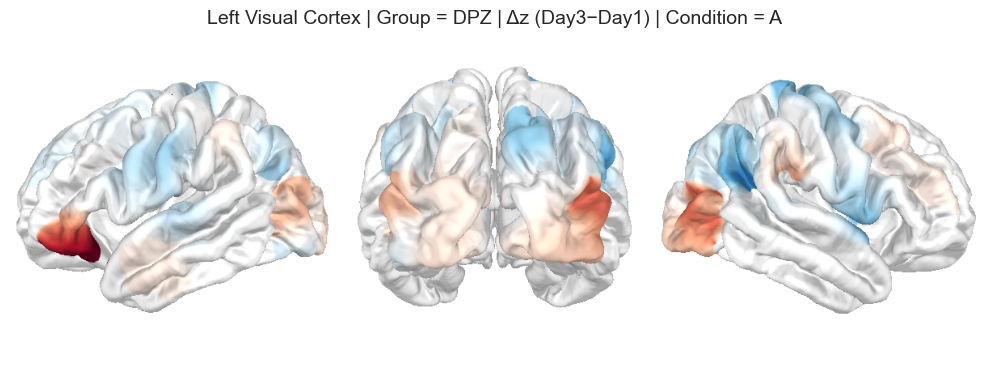

Projecting data from 168 sensors onto 327684 surface vertices: weighted mode
    Projecting sensors onto surface
    Minimum projected intra-sensor distance: 0.0 mm
    160208 / 327684 non-zero vertices


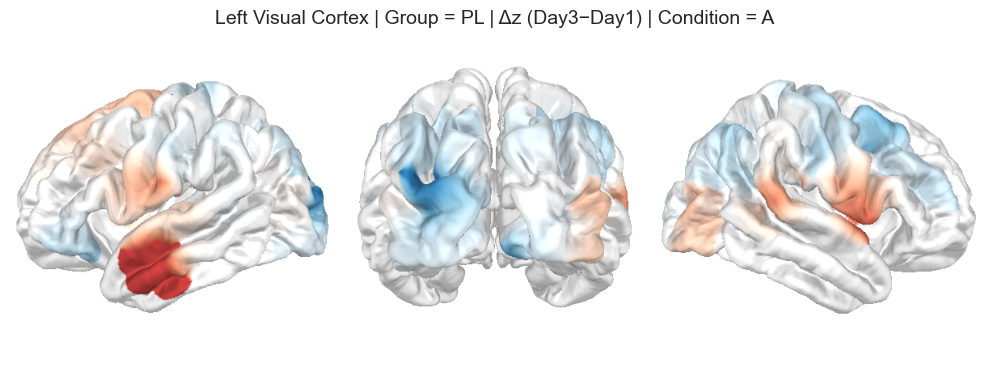

In [121]:
# =========================
# ONE BRAIN PER GROUP — Left Visual Cortex Δz (Day3 − Day1) using z_beta
# Ansley go here
# =========================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import ListedColormap
import mne

# --- Paths (adjust as needed)
results_path = '../../results_DPZ'
proc_path    = '../../processed_DPZ'
subjects_dir = '../../subjects_DPZ'
os.makedirs(results_path, exist_ok=True)

# --- Colormap (diverging)
original_cmap = cm.get_cmap('RdBu_r', 256)
cmap = ListedColormap(original_cmap(np.linspace(0, 1, 256)))

# ============================================================
# 0) INPUT: df_test must contain at least:
#    ['subject','group','condition','channel_clean','ROI','Hemisphere','day','z_beta']
#    day should be 1 / 3 (numeric or castable to Int64)
# ============================================================

# --- normalize labels and day dtype (safe no-ops if already clean)
df_test = df_test.copy()
df_test['ROI']        = df_test['ROI'].astype(str).str.strip()
df_test['Hemisphere'] = df_test['Hemisphere'].astype(str).str.strip()
df_test['group']      = df_test['group'].astype(str).str.strip()
df_test['day']        = pd.to_numeric(df_test['day'], errors='coerce').astype('Int64')

# ============================================================
# 1) Build channel -> ROI(hemi) map from the SAME dataframe
# ============================================================
df_test['ROI_hemi'] = df_test['ROI'] + ' (' + df_test['Hemisphere'].astype(str) + ')'
channel_to_roihemi = (
    df_test[['channel_clean','ROI_hemi']]
    .dropna()
    .groupby('channel_clean', as_index=False)
    .agg(ROI_hemi=('ROI_hemi', lambda s: s.mode().iat[0]))  # deterministic mode
)

# ============================================================
# 2) Compute per-subject, per-channel z_diff = Day3 − Day1, then
#    average across subjects per (group, condition, channel)
# ============================================================
pairwise = (
    df_test.groupby(['subject','group','condition','channel_clean','day'])['z_beta']
           .mean()
           .unstack('day')
           .reindex(columns=[1,3])
           .dropna(subset=[1,3])
           .reset_index()
)
pairwise['z_diff'] = pairwise[3] - pairwise[1]

chan_means = (
    pairwise.groupby(['group','condition','channel_clean'], as_index=False)
            .agg(z_diff_mean=('z_diff','mean'))
            .merge(channel_to_roihemi, on='channel_clean', how='left')  # keep ROI labels
)

# --- Only keep Right Auditory Cortex channels
#chan_means = chan_means[chan_means['ROI_hemi'].eq('Auditory Cortex (Right)')]

# ============================================================
# 3) Load a representative Raw for channel locations (don’t preload)
# ============================================================
raw_file_path = f"{proc_path}/212_3_001_long_hbo_DPZ_raw.fif"
raw = mne.io.read_raw_fif(raw_file_path, preload=False)

# ensure unique, clean channel names (keep base token; append _k if duplicates)
seen, rename_map = {}, {}
for ch in raw.ch_names:
    base = ch.split(' ')[0]
    if base not in seen:
        seen[base] = 0
        rename_map[ch] = base
    else:
        seen[base] += 1
        rename_map[ch] = f"{base}_{seen[base]}"
raw.rename_channels(rename_map)

# ============================================================
# 4) Helper: render a single brain from channel values
#    Expects ch_df with columns ['channel_clean','value']
# ============================================================
def plot_brain_from_channels(raw_obj, ch_df, title_text, out_png):
    # map channel_clean -> raw index (case-insensitive)
    name_to_idx = {nm.lower(): i for i, nm in enumerate(raw_obj.ch_names)}
    vals = np.zeros(len(raw_obj.ch_names), dtype=float)

    for _, r in ch_df.iterrows():
        idx = name_to_idx.get(str(r['channel_clean']).lower(), None)
        if idx is not None and np.isfinite(r['value']):
            vals[idx] = float(r['value'])

    # symmetric robust color limits
    if np.allclose(vals, 0):
        vmax = 1.0
    else:
        vmax = float(max(1e-6, np.nanpercentile(np.abs(vals), 95)))
    vmin = -vmax

    # make a 1-timepoint Evoked to project sensor values to fsaverage
    evoked = mne.EvokedArray(vals[:, np.newaxis], raw_obj.info)
    picks  = np.arange(len(raw_obj.ch_names))

    stc = mne.stc_near_sensors(
        evoked, trans='fsaverage', subject='fsaverage',
        mode='weighted', distance=0.02, project=True, picks=picks,
        subjects_dir=subjects_dir
    )

    brain = stc.plot(
        hemi='both', views=['lat','frontal','lat'],
        cortex='low_contrast', time_viewer=False, show_traces=False,
        surface='pial', smoothing_steps=0, size=(1200, 400),
        clim=dict(kind='value', lims=[-1, 0, 1]),
        colormap=cmap, view_layout='horizontal', colorbar=False,
        time_label='', background='w',
        add_data_kwargs=dict(
            transparent=False,  # <-- prevent grey by disabling transparency below fmin
            colorbar_kwargs=dict(
                title=' ',
                title_font_size=12, label_font_size=8, n_labels=3
            )
        ),
        subjects_dir=subjects_dir
    )
    brain.show_view('lat', hemi='lh', row=0, col=0)
    brain.show_view(azimuth=270, elevation=90, row=0, col=1)
    brain.show_view('lat', hemi='rh', row=0, col=2)

    img = brain.screenshot(time_viewer=False)
    brain.close()

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.imshow(img); ax.set_title(title_text, fontsize=14); ax.axis('off')
    plt.tight_layout()
    plt.savefig(out_png, dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)

# ============================================================
# 5) Plot: one brain per group using z_diff_mean
# ============================================================
all_groups     = sorted(df_test['group'].astype(str).unique())
all_conditions = sorted(df_test['condition'].astype(str).unique())
use_condition  = all_conditions[0] if len(all_conditions) else None

def plot_group(grp):
    sub = chan_means[chan_means['group'].astype(str) == str(grp)].copy()
    if use_condition is not None:
        sub = sub[sub['condition'].astype(str) == str(use_condition)]

    if sub.empty:
        print(f"[skip] No channels to plot for group={grp}")
        return

    title = f"Left Visual Cortex | Group = {grp} | Δz (Day3−Day1)"
    if use_condition is not None:
        title += f" | Condition = {use_condition}"

    out_png = os.path.join(results_path, f"brain_VC-Left_group-{grp}_zdiff.png")
    plot_brain_from_channels(
        raw,
        sub[['channel_clean','z_diff_mean']].rename(columns={'z_diff_mean':'value'}),
        title,
        out_png
    )

for grp in all_groups:
    plot_group(grp)



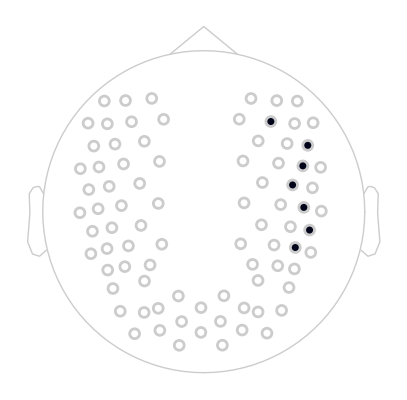

In [105]:
from mne.viz import plot_sensors
import numpy as np
import mne

def _plot_sig_chs_green(raw, sigs, ax, show_names=True):
    info = raw.info

    # --- normalize "sigs" to integer picks (indices into raw.info['ch_names']) ---
    # handle list of tuples like [(idx, ...), ...]
    if len(sigs) and isinstance(sigs[0], tuple):
        sigs = [s[0] for s in sigs]

    if len(sigs) and isinstance(sigs[0], str):
        # convert names -> picks
        sig_picks = mne.pick_channels(info['ch_names'], include=[str(s) for s in sigs])
    else:
        # assume already indices
        sig_picks = np.array(sigs, dtype=int)

    all_picks = mne.pick_types(info)
    other_picks = np.setdiff1d(all_picks, sig_picks)

    # --- plot with two groups so we can recolor reliably ---
    ch_groups = [sig_picks, other_picks]
    fig = mne.viz.plot_sensors(
        info, kind='topomap', axes=ax, pointsize=50,
        ch_groups=ch_groups, show_names=show_names, block=False, title=''
    )

    # force recolor manually
    coll = ax.collections[0]  # PathCollection
    face = coll.get_facecolor()
    n_pts = face.shape[0]

    # mark sig vs. other explicitly by index
    sig_mask = np.zeros(n_pts, dtype=bool)
    for pick in sig_picks:
        if pick < n_pts:
            sig_mask[pick] = True
    other_mask = ~sig_mask

    # assign green to sigs, gray to others
    face[sig_mask] = (0.0, 1.0, 0.0, 0.9)     # bright green
    face[other_mask] = (0.6, 0.6, 0.6, 0.4)   # gray w/ transparency
    coll.set_facecolor(face)
    coll.set_edgecolor('none')

    if show_names:
        for t in ax.texts:
            t.set_fontsize('x-small')
            t.set_zorder(5)


fig, ax = plt.subplots(figsize=(5, 5))
# you can pass indices OR names; examples:

# 1) Pick channels belonging to the two ROIs of interest
mask = (
#    ((df_test['ROI'] == 'Visual Cortex')  & (df_test['Hemisphere'] == 'Left'))# |
    ((df_test['ROI'] == 'Auditory Cortex') & (df_test['Hemisphere'] == 'Right'))
)
sigs_clean = (df_test.loc[mask, 'channel_clean']
              .dropna().astype(str).str.lower().str.strip().unique().tolist())

# 2) Map cleaned names (e.g., 's15_d25') -> actual raw channel names
base_to_raw = {ch.split(' ')[0].lower(): ch for ch in raw.ch_names}
sigs_raw = [base_to_raw[c] for c in sigs_clean if c in base_to_raw]

# 3) Plot: significant channels (the two ROIs) in green; others gray
_plot_sig_chs_green(raw, sigs=sigs_raw, ax=ax, show_names=False)
plt.show()




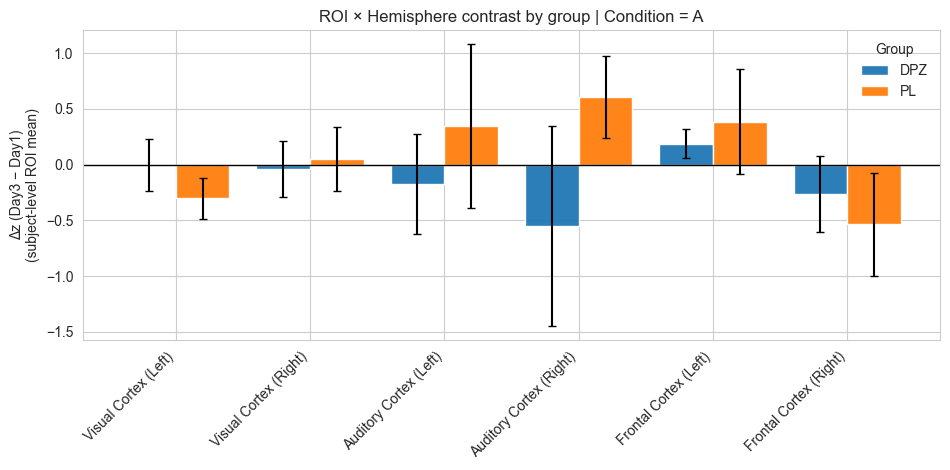

Saved bar plot to: ../../results_DPZ/bars_roi_by_group.png


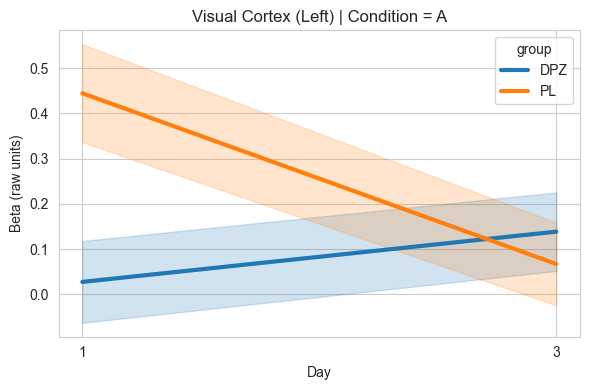

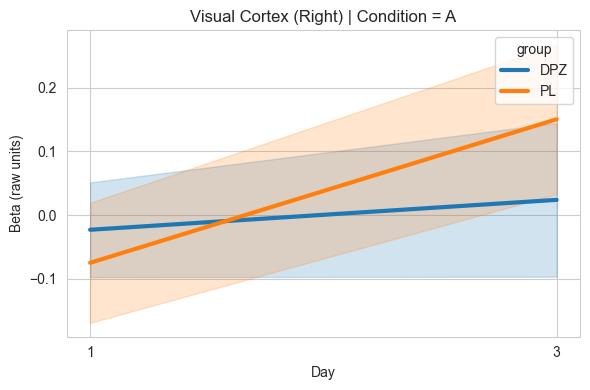

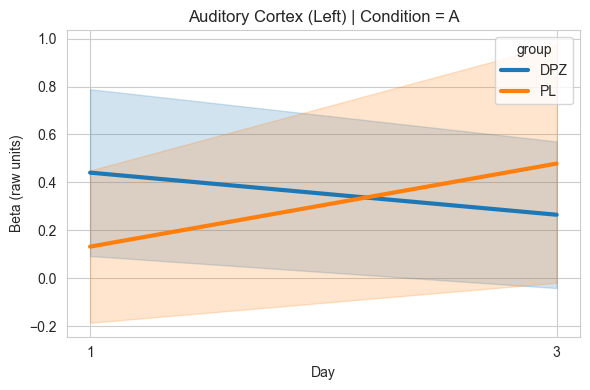

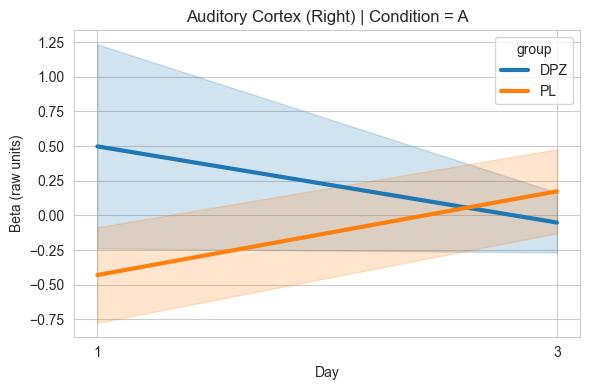

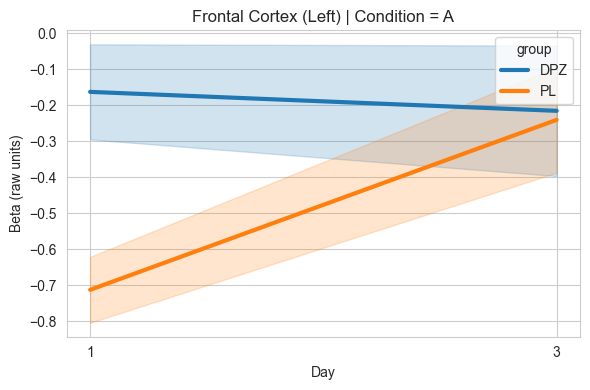

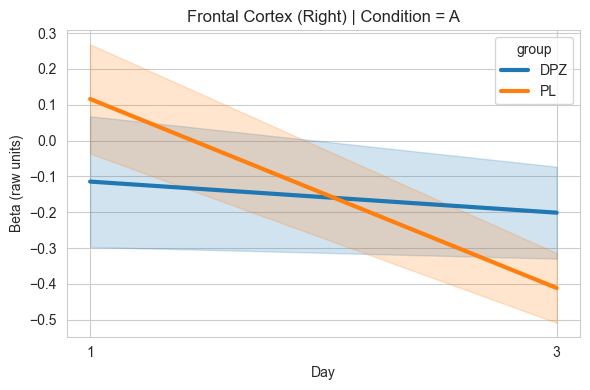

In [5]:
### 09/07/2025: BAR GRAPHS

# =========================
# BAR PLOTS: Δz (Day3−Day1) per ROI×Hemisphere, grouped by group
# =========================
import os
import numpy as np
import matplotlib.pyplot as plt

# where to save (re-uses your results_path if defined earlier)
results_path = globals().get('results_path', '../../results_DPZ')
os.makedirs(results_path, exist_ok=True)

# 1) Compute Δz per subject × channel from your existing z_beta
df_test['day'] = df_test['day'].astype(str)
pv = (
    df_test
    .pivot_table(index=['subject','group','condition','channel_clean'],
                 columns='day', values='z_beta', aggfunc='mean')
    .rename(columns={'1.0':'1','3.0':'3'})
)
for d in ('1','3'):
    if d not in pv.columns:
        pv[d] = np.nan
pv = pv.dropna(subset=['1','3']).reset_index()
pv['z_diff'] = pv['3'] - pv['1']

# 2) Attach the analysis-consistent ROI_hemi to each channel
#    (channel_to_roihemi was created from df_merged above)
pv = pv.merge(channel_to_roihemi, on='channel_clean', how='left')

# 3) Subject-level ROI means (prevents channel-count bias)
roi_subj = (
    pv.groupby(['ROI_hemi','group','subject','condition'], as_index=False)['z_diff']
      .mean()
)

# If you only have 'A', this will just pick it; otherwise change to a specific condition
all_conditions = sorted(roi_subj['condition'].astype(str).unique())
use_condition  = all_conditions[0] if len(all_conditions) else None
if use_condition is not None:
    roi_subj = roi_subj[roi_subj['condition'].astype(str) == str(use_condition)]

# 4) Group-level stats (mean ± SEM) per ROI_hemi × group
stats = (roi_subj.groupby(['ROI_hemi','group'])['z_diff']
         .agg(mean='mean', sd='std', n='count')
         .reset_index())
stats['sem'] = stats['sd'] / np.sqrt(stats['n'].clip(lower=1))

# 5) Arrange for plotting
groups_sorted = sorted(df_test['group'].astype(str).unique())
preferred_order = [
    'Visual Cortex (Left)','Visual Cortex (Right)',
    'Auditory Cortex (Left)','Auditory Cortex (Right)',
    'Frontal Cortex (Left)','Frontal Cortex (Right)'
]
rois_sorted = [r for r in preferred_order if r in stats['ROI_hemi'].unique()]
rois_sorted += [r for r in stats['ROI_hemi'].unique() if r not in rois_sorted]

plot_means = stats.pivot(index='ROI_hemi', columns='group', values='mean').reindex(rois_sorted)
plot_sems  = stats.pivot(index='ROI_hemi', columns='group', values='sem' ).reindex(rois_sorted)

# 6) Plot grouped bars with SEM
x = np.arange(len(rois_sorted))
k = max(1, len(groups_sorted))
width = 0.8 / k

fig, ax = plt.subplots(figsize=(max(8, 1.6*len(rois_sorted)), 4.8))

for i, g in enumerate(groups_sorted):
    means = plot_means[g].values if g in plot_means else np.full(len(rois_sorted), np.nan)
    errs  = plot_sems[g].values  if g in plot_sems  else np.full(len(rois_sorted), np.nan)
    xpos = x + i*width - (k-1)*width/2
    ax.bar(xpos, means, width, yerr=errs, capsize=3, label=str(g), alpha=0.95)

ax.axhline(0, color='k', lw=1)
ax.set_xticks(x)
ax.set_xticklabels(rois_sorted, rotation=45, ha='right')
ax.set_ylabel('Δz (Day3 − Day1)\n(subject-level ROI mean)')
title = "ROI × Hemisphere contrast by group"
if use_condition is not None:
    title += f" | Condition = {use_condition}"
ax.set_title(title)
ax.legend(title='Group', frameon=False)

plt.tight_layout()
out_png = os.path.join(results_path, 'bars_roi_by_group.png')
plt.savefig(out_png, dpi=200, bbox_inches='tight')
plt.show()
print(f"Saved bar plot to: {out_png}")


#####################

import seaborn as sns
sns.set_style("whitegrid")
df_test['day'] = df_test['day'].astype(str)
df_test['day'] = pd.Categorical(df_test['day'], categories=['1.0','3.0','1','3'], ordered=True)

for cond in 'A':
   for roi in rois_sorted:
       sub = df_test[(df_test['ROI_hemi'] == roi) &
                       (df_test['condition'].astype(str) == str(cond))].copy()
       if sub.empty:
           continue

       plt.figure(figsize=(6, 4))
       sns.lineplot(
           data=sub, x='day', y='z_beta', hue='group',
           estimator='mean', errorbar='se', lw=3
       )
       plt.title(f"{roi} | Condition = {cond}")
       plt.ylabel('Beta (raw units)')
       plt.xlabel('Day')
       plt.tight_layout()
       plt.show()


In [5]:
## PLOT THE ABOVE RESULTS ON THE BRAIN - 09/07/25 --> fucked

# =========================
# ONE BRAIN PER GROUP — show Δz where C(group):C(day) p<0.05
# =========================

import os
import mne
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import ListedColormap

results_path = '../../results_DPZ'
proc_path = '../../processed_DPZ'
subjects_dir = '../../subjects_DPZ'
os.makedirs(results_path, exist_ok=True)
original_cmap = cm.get_cmap('RdBu_r', 256)
cmap = ListedColormap(original_cmap(np.linspace(0, 1, 256)))

# ---- Build channel -> ROI_hemi map from *exactly the same* analysis dataframe ----
df_final['ROI_hemi'] = df_final['ROI'] + ' (' + df_final['Hemisphere'].astype(str) + ')'
channel_to_roihemi = (
    df_final[['channel_clean','ROI_hemi']]
    .dropna()
    .groupby('channel_clean', as_index=False)
    .agg(ROI_hemi=('ROI_hemi', lambda s: s.mode().iat[0]))  # deterministic mode
)

# ---- Re-run the same ANOVA per ROI×hemi to get the interaction p-value ----
sig_rois = set()
for roi_name in ['Visual Cortex','Auditory Cortex','Frontal Cortex']:
    sub_roi = df_final[df_final['ROI'] == roi_name]
    if sub_roi.empty:
        continue
    for hemi in sub_roi['Hemisphere'].dropna().unique():
        hemi_df = sub_roi[sub_roi['Hemisphere'] == hemi]
        if hemi_df.empty:
            continue
        model = smf.ols("beta ~ C(group) * C(day)", data=hemi_df).fit()
        aov   = sm.stats.anova_lm(model, typ=2)
        if 'C(group):C(day)' in aov.index:
            pval = aov.loc['C(group):C(day)','PR(>F)']
            if (pval is not None) and np.isfinite(pval) and (pval < 0.05):
                sig_rois.add(f"{roi_name} ({hemi})")

print(f"Significant ROI×hemi (p<0.05): {sorted(sig_rois) if sig_rois else 'None'}")

# ---- Compute Δz = (Day3 − Day1) per subject×channel, then mean across subjects per group ----
df_final['day'] = df_final['day'].astype(str)
pv = (
    df_final
    .pivot_table(index=['subject','group','condition','channel_clean'],
                 columns='day', values='beta', aggfunc='mean')
    .rename(columns={'1.0':'1','3.0':'3'})
)
for d in ('1','3'):
    if d not in pv.columns:
        pv[d] = np.nan
pv = pv.dropna(subset=['1','3']).reset_index()
pv['z_diff'] = pv['3'] - pv['1']

# attach the analysis-consistent ROI_hemi
pv = pv.merge(channel_to_roihemi, on='channel_clean', how='left')

# subject-averaged Δz per group × channel (keep ROI_hemi for filtering)
# 1) Compute ROI×hemi mean Δz per group × condition
roi_means = (
    pv.groupby(['group','condition','ROI_hemi'], as_index=False)
      .agg(z_diff_roi=('z_diff','mean'))
)

# 2) Broadcast that single ROI value to every channel that maps to the ROI (using the SAME mapping as analysis)
#    channel_to_roihemi must come from df_merged as we set earlier.
chan_means = (
    roi_means
    .merge(channel_to_roihemi, on='ROI_hemi', how='left')   # adds channel_clean list for each ROI
    .rename(columns={'z_diff_roi': 'z_diff_mean'})
    # columns now: group, condition, ROI_hemi, z_diff_mean, channel_clean
)


# ---- Load a representative Raw for channel positions (don’t preload) ----
raw_file_path = f"{proc_path}/212_3_001_long_hbo_DPZ_raw.fif"
raw = mne.io.read_raw_fif(raw_file_path, preload=False)

# ensure unique channel names (keep Sx_Dy base; append _k if duplicates)
seen, rename_map = {}, {}
for ch in raw.ch_names:
    base = ch.split(' ')[0]
    if base not in seen:
        seen[base] = 0
        rename_map[ch] = base
    else:
        seen[base] += 1
        rename_map[ch] = f"{base}_{seen[base]}"
raw.rename_channels(rename_map)

# ---- Helper: render a single brain from channel values ----
def plot_brain_from_channels(raw_obj, ch_df, title_text, out_png):
    # map channel_clean -> raw index (case-insensitive)
    name_to_idx = {nm.lower(): i for i, nm in enumerate(raw_obj.ch_names)}
    vals = np.zeros(len(raw_obj.ch_names), dtype=float)
    for _, r in ch_df.iterrows():
        idx = name_to_idx.get(str(r['channel_clean']).lower(), None)
        if idx is not None and np.isfinite(r['z_diff_mean']):
            vals[idx] = r['z_diff_mean']

    # symmetric robust color limits
    if np.allclose(vals, 0):
        vmax = 1.0
    else:
        vmax = float(max(1e-6, np.nanpercentile(np.abs(vals), 95)))
    vmin = -vmax

    evoked = mne.EvokedArray(vals[:, np.newaxis], raw_obj.info)
    picks  = np.arange(len(raw_obj.ch_names))
    stc = mne.stc_near_sensors(
    evoked, trans='fsaverage', subject='fsaverage',
    mode='nearest',          # no blending across neighbors
    distance=0.02,         # tighter footprint around each channel (was 0.02)
    project=True, picks=picks, subjects_dir=subjects_dir)
    brain = stc.plot(
        hemi='both', views=['lat','frontal','lat'],
        cortex='low_contrast', time_viewer=False, show_traces=False,
        surface='pial', smoothing_steps=0, size=(1200, 400),
        clim=dict(kind='value', lims=[vmin/200, 0, vmax/50]),
        colormap=cmap, view_layout='horizontal', colorbar=True,
        time_label='', background='w',
        add_data_kwargs=dict(colorbar_kwargs=dict(
            title='Δz (Day3 − Day1)', title_font_size=12, label_font_size=8, n_labels=3
        )),
        subjects_dir=subjects_dir
    )
    brain.show_view('lat', hemi='lh', row=0, col=0)
    brain.show_view(azimuth=270, elevation=90, row=0, col=1)
    brain.show_view('lat', hemi='rh', row=0, col=2)

    img = brain.screenshot(time_viewer=False)
    brain.close()

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.imshow(img); ax.set_title(title_text, fontsize=14); ax.axis('off')
    plt.tight_layout()
    plt.savefig(out_png, dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)

# ---- One brain per group: only channels from significant ROI×hemi are colored ----
all_groups     = sorted(df_final['group'].astype(str).unique())
all_conditions = sorted(df_final['condition'].astype(str).unique())
use_condition  = all_conditions[0] if len(all_conditions) else None

if not sig_rois:
    print("[info] No ROI×hemi passed p<0.05; no brains will be saved.")
else:
    for grp in all_groups:
        sub = chan_means[chan_means['group'].astype(str) == str(grp)].copy()
        if use_condition is not None:
            sub = sub[sub['condition'].astype(str) == str(use_condition)]
        if sub.empty:
            print(f"[skip] No channel means for group={grp}"); continue

        # keep only channels whose ROI_hemi is in the significant set
        sub = sub[sub['ROI_hemi'].isin(sig_rois)]
        if sub.empty:
            print(f"[skip] No significant channels for group={grp}"); continue

        title = f"Group = {grp}"
        if use_condition is not None:
            title += f" | Condition = {use_condition}"
        title += " | ROIs: " + ", ".join(sorted(sig_rois))

        out_png = os.path.join(results_path, f"brain_sigROIs_combined_group-{grp}.png")
        plot_brain_from_channels(raw, sub[['channel_clean','z_diff_mean']], title, out_png)

print("Done.")


KeyError: 'ROI'

Opening raw data file ../../processed_DPZ/212_3_001_long_hbo_DPZ_raw.fif...
    Range : 0 ... 3935 =      0.000 ...   818.480 secs
Ready.
Projecting data from 168 sensors onto 327684 surface vertices: sum mode
    Projecting sensors onto surface
    Minimum projected intra-sensor distance: 0.0 mm
    160208 / 327684 non-zero vertices


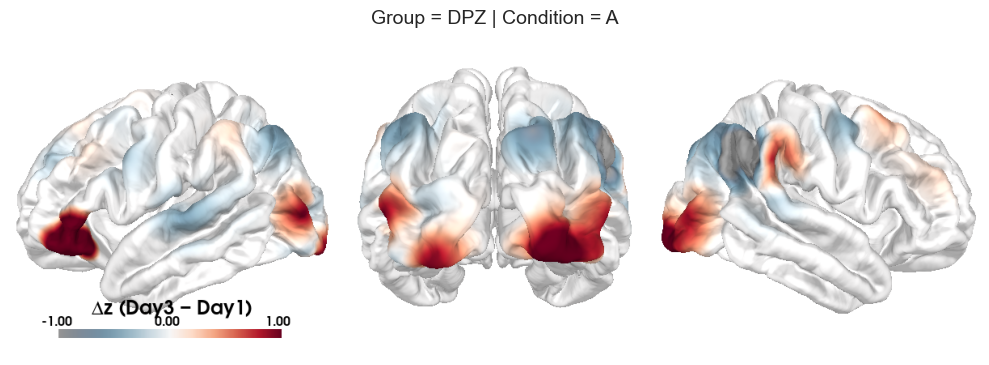

Projecting data from 168 sensors onto 327684 surface vertices: sum mode
    Projecting sensors onto surface
    Minimum projected intra-sensor distance: 0.0 mm
    160208 / 327684 non-zero vertices


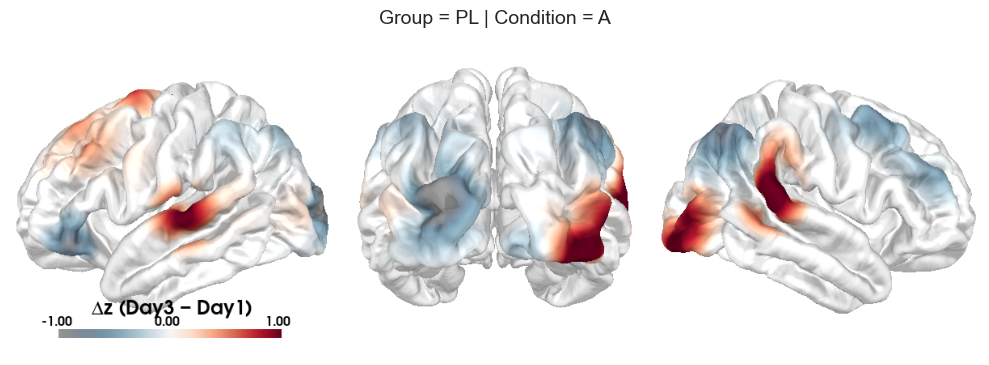

Saved one brain per group with mean Δz per channel to: ../../results_DPZ


In [82]:
## PLOT THE ABOVE RESULTS AGAIN - 09/07/25 

# =========================
# ONE BRAIN PER GROUP — mean Δz per channel (Day3−Day1)
# =========================
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import mne

# Paths (reuse if already defined)
results_path = globals().get('results_path', '../../results_DPZ')
proc_path    = globals().get('proc_path',    '../../processed_DPZ')
subjects_dir = globals().get('subjects_dir', '../../subjects_DPZ')
os.makedirs(results_path, exist_ok=True)

# 1) Build Δz per subject×channel from your z_beta, then average per group (and condition if present)
df_merged['day'] = df_merged['day'].astype(str)
pv = (
    df_merged
    .pivot_table(index=['subject','group','condition','channel_clean'],
                 columns='day', values='z_beta', aggfunc='mean')
    .rename(columns={'1.0':'1','3.0':'3'})
)
for d in ('1','3'):
    if d not in pv.columns:
        pv[d] = np.nan
pv = pv.dropna(subset=['1','3']).reset_index()
pv['z_diff'] = pv['3'] - pv['1']

# mean Δz per group × condition × channel
chan_means = (
    pv.groupby(['group','condition','channel_clean'], as_index=False)
      .agg(z_diff_mean=('z_diff','mean'))
)

# 2) Load a representative Raw for channel positions (no preload)
raw_file_path = f"{proc_path}/212_3_001_long_hbo_DPZ_raw.fif"
raw = mne.io.read_raw_fif(raw_file_path, preload=False)

# Ensure unique Raw channel names (keep Sx_Dy base; append suffix if duplicates)
seen, rename_map = {}, {}
for ch in raw.ch_names:
    base = ch.split(' ')[0]
    if base not in seen:
        seen[base] = 0
        rename_map[ch] = base
    else:
        seen[base] += 1
        rename_map[ch] = f"{base}_{seen[base]}"
raw.rename_channels(rename_map)

# 3) Colormap: use your custom_cmap if present; else default
if 'custom_cmap' in globals():
    cmap = custom_cmap
else:
    cmap = LinearSegmentedColormap.from_list("blue_white_red", ["blue","white","red"], N=256)

# Helper to render a single brain from channel values
def plot_brain_from_channels(raw_obj, ch_df, title_text, out_png):
    # Map channel_clean -> raw index (case-insensitive), with suffix fallback (e.g., S15_D11 -> S15_D11_1)
    name_to_idx = {nm.lower(): i for i, nm in enumerate(raw_obj.ch_names)}
    vals = np.zeros(len(raw_obj.ch_names), dtype=float)
    for _, r in ch_df.iterrows():
        nm = str(r['channel_clean']).lower()
        idx = name_to_idx.get(nm)
        if idx is None:
            for k in name_to_idx.keys():
                if k == nm or k.startswith(nm + "_"):
                    idx = name_to_idx[k]; break
        if idx is not None and np.isfinite(r['z_diff_mean']):
            vals[idx] = r['z_diff_mean']

    # Symmetric robust color limits
    vmax = float(max(1e-6, np.nanpercentile(np.abs(vals), 95))) if not np.allclose(vals, 0) else 1.0
    vmin = -vmax

    evoked = mne.EvokedArray(vals[:, np.newaxis], raw_obj.info)
    picks  = np.arange(len(raw_obj.ch_names))
    stc = mne.stc_near_sensors(
        evoked, trans='fsaverage', subject='fsaverage',
        mode='sum',              # per-channel, minimal blending
        distance=0.02,             # tight footprint per channel
        project=True, picks=picks, subjects_dir=subjects_dir
    )
    brain = stc.plot(
        hemi='both', views=['lat','frontal','lat'],
        cortex='low_contrast', time_viewer=False, show_traces=False,
        surface='pial', smoothing_steps=0, size=(1200, 400),
        clim=dict(kind='value', lims=[-1, 0.0, 1]),
        colormap=cmap, view_layout='horizontal', colorbar=True,
        time_label='', background='w',
        add_data_kwargs=dict(colorbar_kwargs=dict(
            title='Δz (Day3 − Day1)', title_font_size=12, label_font_size=8, n_labels=3
        )),
        subjects_dir=subjects_dir
    )
    brain.show_view('lat', hemi='lh', row=0, col=0)
    brain.show_view(azimuth=270, elevation=90, row=0, col=1)
    brain.show_view('lat', hemi='rh', row=0, col=2)

    img = brain.screenshot(time_viewer=False)
    brain.close()

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.imshow(img); ax.set_title(title_text, fontsize=14); ax.axis('off')
    plt.tight_layout()
    plt.savefig(out_png, dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)

# 4) One brain per group (uses the first/only condition; change if needed)
all_groups     = sorted(df_merged['group'].astype(str).unique())
all_conditions = sorted(df_merged['condition'].astype(str).unique())
use_condition  = all_conditions[0] if len(all_conditions) else None

for grp in all_groups:
    sub = chan_means[chan_means['group'].astype(str) == str(grp)].copy()
    if use_condition is not None:
        sub = sub[sub['condition'].astype(str) == str(use_condition)]
    if sub.empty:
        print(f"[skip] No channel means for group={grp}"); continue

    title = f"Group = {grp}"
    if use_condition is not None:
        title += f" | Condition = {use_condition}"
    out_png = os.path.join(results_path, f"brain_mean_zdiff_per_channel_group-{grp}.png")

    plot_brain_from_channels(raw, sub[['channel_clean','z_diff_mean']], title, out_png)

print("Saved one brain per group with mean Δz per channel to:", results_path)



In [3]:
# === 8. Sanity checks ===
print("\n=== df_merged preview ===")
print(df_merged.head())

print("\nColumns in df_merged:", df_merged.columns.tolist())
print("\nUnique ROIs in df_merged:", df_merged['ROI'].unique())
print("Unique Hemispheres in df_merged:", df_merged['Hemisphere'].unique())
print("Subjects in df_merged:", sorted(df_merged['subject'].unique()))

print("\nCheck for missing values in df_merged:")
print(df_merged.isnull().sum())

print("\nZ-score summary (should be roughly mean=0, std=1):")
print(df_merged.groupby(['subject', 'day', 'chroma'])['z_beta'].agg(['mean', 'std']).describe())

print("\n=== agg_df preview ===")
print(agg_df.head())

print("\nUnique subjects × ROI × Hemisphere × day in agg_df:")
print(agg_df.groupby(['ROI', 'Hemisphere', 'day'])['subject'].nunique())



=== df_merged preview ===
   group  subject condition chroma channel_clean          beta  day  \
34   DPZ    201.0         A    hbo       s12_d20 -3.963764e-08  1.0   
41   DPZ    201.0         A    hbo       s12_d20  6.910838e-08  3.0   
48   DPZ    201.0         A    hbo       s12_d22  2.627905e-08  1.0   
54   DPZ    201.0         A    hbo       s12_d22  6.910838e-08  3.0   
61   DPZ    201.0         A    hbo       s12_d24 -1.098161e-07  1.0   

   ch_name_clean                                      Landmark Hemisphere  \
34       s12_d20  42 - Primary and Auditory Association Cortex      Right   
41       s12_d20  42 - Primary and Auditory Association Cortex      Right   
48       s12_d22  42 - Primary and Auditory Association Cortex      Right   
54       s12_d22  42 - Primary and Auditory Association Cortex      Right   
61       s12_d24  42 - Primary and Auditory Association Cortex      Right   

    Specificity              ROI    z_beta  weighted_z  
34     7.784745  Auditory 

In [4]:
## Similar analysis but with FDR correction
 
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

# === 1. Clean and threshold specificity info
specificity_df_clean = specificity_df.copy()
specificity_df_clean['ch_name_clean'] = (
    specificity_df_clean['ch_name']
    .str.strip()
    .str.lower()
    .str.replace(' hbo', '', regex=False)
)
specificity_df_clean = specificity_df_clean[specificity_df_clean['Specificity'] >= 0.1]

# === 2. Build per-subject beta values from df_final
groups = df_final['group'].unique()
conditions = ['A']
chromas = ['hbo']
records = []

for chroma in chromas:
    for condition in conditions:
        df_condition = df_final.query(f"Chroma == '{chroma}' and Condition == '{condition}'").copy()
        df_condition['day'] = df_condition['day'].astype(float)
        df_condition['subject'] = df_condition['subject'].astype(float)

        for group in groups:
            df_group = df_condition[df_condition['group'] == group]
            for subject in df_group['subject'].unique():
                df_subject = df_group[df_group['subject'] == subject]
                df_day1 = df_subject[df_subject['day'] == 1.0].set_index('ch_name')['theta']
                df_day3 = df_subject[df_subject['day'] == 3.0].set_index('ch_name')['theta']

                common_channels = df_day1.index.intersection(df_day3.index)
                for ch in common_channels:
                    ch_clean = ch.strip().lower().replace(" hbo", "").replace(" hbdiff", "")
                    records.append({
                        'group': group,
                        'subject': subject,
                        'condition': condition,
                        'chroma': chroma,
                        'channel_clean': ch_clean,
                        'beta': df_day1.loc[ch],
                        'day': 1.0
                    })
                    records.append({
                        'group': group,
                        'subject': subject,
                        'condition': condition,
                        'chroma': chroma,
                        'channel_clean': ch_clean,
                        'beta': df_day3.loc[ch],
                        'day': 3.0
                    })

df_beta_long = pd.DataFrame(records)

# === 3. Merge beta with specificity info
df_merged = df_beta_long.merge(
    specificity_df_clean[['ch_name_clean', 'Landmark', 'Specificity', 'Hemisphere']],
    left_on='channel_clean',
    right_on='ch_name_clean',
    how='inner'
)

# === 4. Collapse landmarks to ROI, preserving hemisphere
def classify_roi(landmark):
    if isinstance(landmark, str):
        if any(x in landmark for x in ['Visual', 'V1', 'V2', 'V3']):
            return 'Visual Cortex'
        elif 'Auditory' in landmark:
            return 'Auditory Cortex'
    return None  # Skip unknown ROIs

df_merged['ROI_base'] = df_merged['Landmark'].apply(classify_roi)
df_merged = df_merged[df_merged['ROI_base'].notna()]
df_merged['ROI'] = df_merged['ROI_base'] + ' - ' + df_merged['Hemisphere'].str.capitalize()

# === 5. Compute weighted beta per subject × ROI × day
weighted_agg = (
    df_merged
    .groupby(['subject', 'ROI', 'group', 'day'])
    .apply(lambda x: np.average(x['beta'], weights=x['Specificity']))
    .reset_index(name='ROI_beta')
)

# === 6. Run ANOVAs
roi_anova_results = {}
roi_pvals = []
roi_labels = []

for roi in weighted_agg['ROI'].dropna().unique():
    roi_df = weighted_agg[weighted_agg['ROI'] == roi]
    if roi_df['subject'].nunique() > 2:
        model = smf.ols("ROI_beta ~ C(group) * C(day)", data=roi_df).fit()
        anova_results = sm.stats.anova_lm(model, typ=2)
        roi_anova_results[roi] = anova_results
        p = anova_results.loc['C(group):C(day)', 'PR(>F)']
        roi_pvals.append(p)
        roi_labels.append(roi)
        print(f"\n=== ANOVA for {roi} ===")
        print(anova_results)
    else:
        print(f"\n[!] Skipped {roi}: not enough subjects.")

# === 7. FDR correction

# Filter to hemisphere-specific ROIs under your target base ROIs
target_bases = ['Visual Cortex', 'Auditory Cortex']
hemi_roi_labels = [roi for roi in roi_labels if roi.split(' - ')[0] in target_bases]
hemi_roi_pvals = [pval for roi, pval in zip(roi_labels, roi_pvals) if roi.split(' - ')[0] in target_bases]

# Apply FDR correction over the 4 hemisphere-specific comparisons
rejected, pvals_corrected, _, _ = multipletests(hemi_roi_pvals, method='fdr_bh')

# Print corrected p-values per hemisphere-specific ROI
print("\n=== FDR-corrected p-values for group × day interaction (4 hemisphere-specific comparisons) ===")
for roi, p_unc, p_corr, sig in zip(hemi_roi_labels, hemi_roi_pvals, pvals_corrected, rejected):
    print(f"{roi:30s}  p_uncorrected={p_unc:.4f}  p_fdr={p_corr:.4f}  {'*' if sig else ''}")



=== ANOVA for Auditory Cortex - Left ===
                       sum_sq    df         F    PR(>F)
C(group)         4.675466e-15   1.0  0.498885  0.493477
C(day)           1.660311e-16   1.0  0.017716  0.896319
C(group):C(day)  5.760142e-16   1.0  0.061462  0.808391
Residual         1.124621e-13  12.0       NaN       NaN

=== ANOVA for Auditory Cortex - Right ===
                       sum_sq    df         F    PR(>F)
C(group)         3.394551e-14   1.0  1.003441  0.336251
C(day)           7.841894e-16   1.0  0.023181  0.881517
C(group):C(day)  3.716953e-14   1.0  1.098745  0.315196
Residual         4.059491e-13  12.0       NaN       NaN

=== ANOVA for Visual Cortex - Left ===
                       sum_sq    df         F    PR(>F)
C(group)         4.251449e-16   1.0  0.039667  0.845467
C(day)           6.736809e-15   1.0  0.628566  0.443275
C(group):C(day)  6.721108e-15   1.0  0.627101  0.443793
Residual         1.286129e-13  12.0       NaN       NaN

=== ANOVA for Visual Cortex - Righ

/var/folders/dv/s4k5_3r51ml3q36bgbcdsgbr0000gn/T/ipykernel_98915/2936948607.py:85: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_merged



=== FDR-corrected significant interaction effects (p_corr < 0.05) ===
Channel: S11_D19 hbo     | Hemisphere: Right  | FDR-corrected p = 0.0068
Channel: S12_D22 hbo     | Hemisphere: Right  | FDR-corrected p = 0.0007
Channel: S1_D4 hbo       | Hemisphere: Left   | FDR-corrected p = 0.0001
Channel: S20_D7 hbo      | Hemisphere: Left   | FDR-corrected p = 0.0055
Channel: S21_D7 hbo      | Hemisphere: Left   | FDR-corrected p = 0.0290
Channel: S24_D10 hbo     | Hemisphere: Left   | FDR-corrected p = 0.0062
Channel: S25_D11 hbo     | Hemisphere: Left   | FDR-corrected p = 0.0006
Channel: S25_D13 hbo     | Hemisphere: Left   | FDR-corrected p = 0.0007
Channel: S25_D14 hbo     | Hemisphere: Left   | FDR-corrected p = 0.0403
Channel: S3_D6 hbo       | Hemisphere: Left   | FDR-corrected p = 0.0001
Channel: S4_D5 hbo       | Hemisphere: Left   | FDR-corrected p = 0.0002
Channel: S7_D17 hbo      | Hemisphere: Right  | FDR-corrected p = 0.0089
Channel: S8_D18 hbo      | Hemisphere: Right  | FDR-c

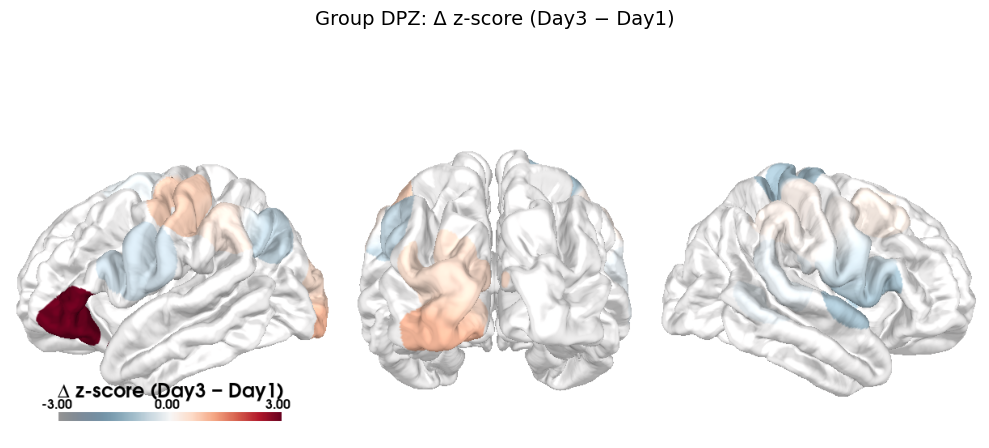

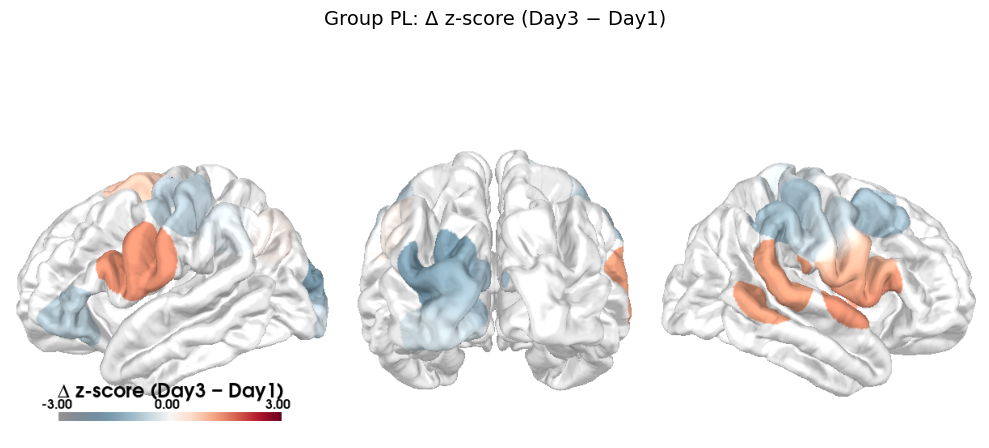

In [ ]:
# Analyze by channel and hemisphere with FDR correction
 
import pandas as pd
import numpy as np
import mne
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from scipy.stats import zscore
import matplotlib.pyplot as plt

# === 1. Prepare beta records ===
groups = df_final['group'].unique()
conditions = ['A']
chromas = ['hbo']
records = []
subjects_dir = '../../subjects_DPZ'

for chroma in chromas:
    for condition in conditions:
        df_condition = df_final.query(f"Chroma == '{chroma}' and Condition == '{condition}'").copy()
        df_condition['day'] = df_condition['day'].astype(float)
        df_condition['subject'] = df_condition['subject'].astype(float)

        for group in groups:
            df_group = df_condition[df_condition['group'] == group]
            for subject in df_group['subject'].unique():
                df_subject = df_group[df_group['subject'] == subject]
                df_day1 = df_subject[df_subject['day'] == 1.0].set_index('ch_name')['theta']
                df_day3 = df_subject[df_subject['day'] == 3.0].set_index('ch_name')['theta']

                common_channels = df_day1.index.intersection(df_day3.index)
                for ch in common_channels:
                    records.append({
                        'group': group,
                        'subject': subject,
                        'condition': condition,
                        'chroma': chroma,
                        'channel': ch,
                        'beta': df_day1.loc[ch],
                        'day': 1.0
                    })
                    records.append({
                        'group': group,
                        'subject': subject,
                        'condition': condition,
                        'chroma': chroma,
                        'channel': ch,
                        'beta': df_day3.loc[ch],
                        'day': 3.0
                    })

df_channel = pd.DataFrame(records)

# === 2. Merge in Hemisphere info if available ===
# Assuming specificity_df contains the hemisphere info for channels
specificity_df_clean = specificity_df.copy()
specificity_df_clean['ch_name_clean'] = specificity_df_clean['ch_name'].str.strip().str.lower().str.replace(' hbo', '', regex=False)
df_channel['channel_clean'] = df_channel['channel'].str.strip().str.lower().str.replace(' hbo', '', regex=False)

df_channel = df_channel.merge(
    specificity_df_clean[['ch_name_clean', 'Hemisphere']],
    left_on='channel_clean',
    right_on='ch_name_clean',
    how='left'
)

# === 3. Z-score per subject × day × chroma
df_channel['z_beta'] = df_channel.groupby(['subject', 'day', 'chroma'])['beta'].transform(zscore)

# === 4. Run ANOVA per channel and store interaction p-values ===
anova_results_list = []
channel_list = []
hemi_list = []
unique_channels = df_channel['channel'].unique()

for ch in unique_channels:
    ch_df = df_channel[df_channel['channel'] == ch]
    if len(ch_df['subject'].unique()) >= 2:
        model = smf.ols("z_beta ~ C(group) * C(day)", data=ch_df).fit()
        anova = sm.stats.anova_lm(model, typ=2)
        if 'C(group):C(day)' in anova.index:
            pval = anova.loc['C(group):C(day)', 'PR(>F)']
            anova_results_list.append(pval)
            channel_list.append(ch)
            hemi_list.append(ch_df['Hemisphere'].iloc[0] if 'Hemisphere' in ch_df.columns else 'Unknown')

# === 5. FDR correction across channels
rejected, pvals_corrected, _, _ = multipletests(anova_results_list, method='fdr_bh')

# === 6. Print only significant results after correction
print("\n=== FDR-corrected significant interaction effects (p_corr < 0.05) ===")
for ch, hemi, p_corr, keep in zip(channel_list, hemi_list, pvals_corrected, rejected):
    if keep:
        print(f"Channel: {ch:15s} | Hemisphere: {hemi:6s} | FDR-corrected p = {p_corr:.4f}")

sig_channels = [ch for ch, keep in zip(channel_list, rejected) if keep]
sig_df = pd.DataFrame({'channel': sig_channels})
sig_df['ch_name_clean'] = sig_df['channel'].str.lower().str.strip().str.replace(' hbo', '', regex=False)

spec_df_lookup = specificity_df[['ch_name', 'Landmark', 'Hemisphere', 'Specificity']].copy()
spec_df_lookup['ch_name_clean'] = spec_df_lookup['ch_name'].str.lower().str.strip().str.replace(' hbo', '', regex=False)

sig_annotated_all = sig_df.merge(spec_df_lookup, on='ch_name_clean', how='left')

# Print all landmarks + specificity per significant channel
for ch in sig_df['channel']:
    matches = sig_annotated_all[sig_annotated_all['channel'] == ch]
    print(f"\nChannel: {ch}")
    if matches.empty or matches['Landmark'].isna().all():
        print("  ⚠️ No landmark/specificity info found.")
    else:
        for _, row in matches.iterrows():
            print(f"  Hemisphere: {row['Hemisphere']}, Landmark: {row['Landmark']}, Specificity: {row['Specificity']:.2f}")

# Filter out any rows without a match in raw
proc_path = '../../processed_DPZ'
raw_file_path = f"{proc_path}/212_3_001_long_hbo_DPZ_raw.fif"
raw = mne.io.read_raw_fif(raw_file_path, preload=True)
raw.load_data()
sig_ch_names = sig_annotated_all['channel'].unique()
highlight_channels = [ch for ch in sig_ch_names if ch in raw.ch_names]

if not highlight_channels:
    print("⚠️ No significant channels found in raw — skipping brain plot")
else:
    print(f"\n🧠 Plotting significant channels on brain: {highlight_channels}")

    # Copy raw and pick only significant channels
    raw_sig = raw.copy().pick_channels(highlight_channels)

    # Compute z-score difference (Day 3 − Day 1) for each sig. channel
    highlight_values = []
    for ch in raw_sig.ch_names:
        z_day1 = df_channel[(df_channel['channel'] == ch) & (df_channel['day'] == 1.0)]['z_beta'].mean()
        z_day3 = df_channel[(df_channel['channel'] == ch) & (df_channel['day'] == 3.0)]['z_beta'].mean()
        diff = z_day3 - z_day1
        highlight_values.append(diff)

    highlight_values = np.array(highlight_values)
    evoked = mne.EvokedArray(highlight_values[:, np.newaxis], raw_sig.info)

    # Create STC (source time course) near sensor projection
    picks = np.arange(len(raw_sig.ch_names))
    try:
        stc = mne.stc_near_sensors(
            evoked, trans='fsaverage', subject='fsaverage', mode='weighted',
            distance=0.02, project=True, picks=picks, subjects_dir=subjects_dir
        )
    except Exception as e:
        print(f"❌ STC creation failed: {e}")
        stc = None

    if stc:
        try:
            for group in df_channel['group'].unique():
                print(f"\n🧠 Plotting for group: {group}")
                
                # Filter to sig channels and this group
                group_df = df_channel[df_channel['group'] == group]
                group_means = []
                ch_names_in_group = []
                
                for ch in highlight_channels:
                    z_day1 = group_df[(group_df['channel'] == ch) & (group_df['day'] == 1.0)]['z_beta'].mean()
                    z_day3 = group_df[(group_df['channel'] == ch) & (group_df['day'] == 3.0)]['z_beta'].mean()
                    if not np.isnan(z_day1) and not np.isnan(z_day3):
                        group_means.append(z_day3 - z_day1)
                        ch_names_in_group.append(ch)

                if not group_means:
                    print(f"⚠️ No usable data for group {group} — skipping plot")
                    continue

                # Pick channels that exist in raw
                raw_group = raw.copy().pick_channels(ch_names_in_group)
                highlight_values = np.array(group_means)
                evoked = mne.EvokedArray(highlight_values[:, np.newaxis], raw_group.info)
                picks = np.arange(len(raw_group.ch_names))

                try:
                    stc = mne.stc_near_sensors(
                        evoked, trans='fsaverage', subject='fsaverage', mode='weighted',
                        distance=0.02, project=True, picks=picks, subjects_dir=subjects_dir
                    )
                except Exception as e:
                    print(f"❌ STC creation failed for group {group}: {e}")
                    continue

                try:
                    brain = stc.plot(
                        hemi='both', views=['lat', 'frontal', 'lat'],
                        cortex='low_contrast', time_viewer=False, show_traces=False,
                        surface='pial', smoothing_steps=0, size=(1200, 400),
                        clim=dict(kind='value', lims=[-3, 0, 3]),
                        colormap='RdBu_r', view_layout='horizontal',
                        colorbar=True, time_label='', background='w',
                        brain_kwargs=dict(units='m'),
                        add_data_kwargs=dict(colorbar_kwargs=dict(
                            title_font_size=12, label_font_size=8, n_labels=3, title='Δ z-score (Day3 − Day1)'
                        )),
                        subjects_dir=subjects_dir
                    )
                    brain.show_view('lat', hemi='lh', row=0, col=0)
                    brain.show_view(azimuth=270, elevation=90, row=0, col=1)
                    brain.show_view('lat', hemi='rh', row=0, col=2)

                    screenshot = brain.screenshot(time_viewer=False)
                    brain.close()

                    fig, ax = plt.subplots(figsize=(10, 5))
                    ax.imshow(screenshot)
                    ax.axis('off')
                    plt.suptitle(f"Group {group}: Δ z-score (Day3 − Day1)", fontsize=14, y=0.98)
                    plt.tight_layout(rect=[0, 0, 1, 0.96])
                    out_path = f"{results_path}/group_{group}_brain_plot.png"
                    plt.savefig(out_path)
                    print(f"✅ Saved plot for group {group} to {out_path}")

                except Exception as e:
                    print(f"❌ Brain plotting failed for group {group}: {e}")
                    
        except Exception as e:
            print(f"❌ Error in group plotting loop: {e}")


In [7]:
# z_score the theta weights by subject and day,
# combine channels by hemisphere and ROI, weighted by specificity
# and run ANOVA on the ROIs


# what happens if I dont separate by hemisphere?


import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import zscore

# === 1. Clean specificity_df ===
specificity_df_clean = specificity_df.copy()
specificity_df_clean['ch_name_clean'] = (
    specificity_df_clean['ch_name']
    .str.strip()
    .str.lower()
    .str.replace(' hbo', '', regex=False)
)

# Only keep rows with Specificity >= 10%
#specificity_df_clean = specificity_df_clean[specificity_df_clean['Specificity'] >= 0.1]

# === 2. Prepare beta records ===
groups = df_final['group'].unique()
conditions = ['A']
chromas = ['hbo']
records = []

for chroma in chromas:
    for condition in conditions:
        df_condition = df_final.query(f"Chroma == '{chroma}' and Condition == '{condition}'").copy()
        df_condition['day'] = df_condition['day'].astype(float)
        df_condition['subject'] = df_condition['subject'].astype(float)

        for group in groups:
            df_group = df_condition[df_condition['group'] == group]
            for subject in df_group['subject'].unique():
                df_subject = df_group[df_group['subject'] == subject]
                df_day1 = df_subject[df_subject['day'] == 1.0].set_index('ch_name')['theta']
                df_day3 = df_subject[df_subject['day'] == 3.0].set_index('ch_name')['theta']

                common_channels = df_day1.index.intersection(df_day3.index)
                for ch in common_channels:
                    ch_clean = ch.strip().lower().replace(" hbo", "").replace(" hbdiff", "")
                    records.append({
                        'group': group,
                        'subject': subject,
                        'condition': condition,
                        'chroma': chroma,
                        'channel_clean': ch_clean,
                        'beta': df_day1.loc[ch],
                        'day': 1.0
                    })
                    records.append({
                        'group': group,
                        'subject': subject,
                        'condition': condition,
                        'chroma': chroma,
                        'channel_clean': ch_clean,
                        'beta': df_day3.loc[ch],
                        'day': 3.0
                    })

df_beta_long = pd.DataFrame(records)

# === 3. Merge with filtered specificity info ===
df_merged = df_beta_long.merge(
    specificity_df_clean[['ch_name_clean', 'Landmark', 'Hemisphere', 'Specificity']],
    left_on='channel_clean',
    right_on='ch_name_clean',
    how='inner'
)

# === 4. Assign ROIs ===
def classify_roi(landmark):
    if not isinstance(landmark, str):
        return None
    landmark_lower = landmark.lower()
    if any(k in landmark_lower for k in ['visual', 'v1', 'v2', 'v3']):
        return 'Visual Cortex'
    elif any(k in landmark_lower for k in ['auditory', 'a1', 'a2']):
        return 'Auditory Cortex'
    elif any(k in landmark_lower for k in ['frontal', 'prefrontal']):
        return 'Frontal Cortex'
    return None

df_merged['ROI'] = df_merged['Landmark'].apply(classify_roi)
df_merged = df_merged[df_merged['ROI'].notna()]

# === 5. Z-score theta per subject × day × chroma
df_merged['z_beta'] = df_merged.groupby(['subject', 'day'])['beta'].transform(zscore)

# === 6. Compute specificity-weighted z_beta averages per ROI
df_merged['weighted_z'] = df_merged['z_beta'] * df_merged['Specificity']
agg_df = (
    df_merged.groupby(['subject', 'ROI', 'group', 'day'])
    .agg(
        ROI_beta=('weighted_z', lambda x: x.sum()),  # numerator
        weight_sum=('Specificity', lambda x: x.sum())  # denominator
    )
    .reset_index()
)
agg_df['ROI_beta'] = agg_df['ROI_beta'] / agg_df['weight_sum']  # finalize weighted avg

# === 7. Run ANOVA per ROI × Hemisphere
for roi_name in ['Visual Cortex', 'Auditory Cortex', 'Frontal Cortex']:
    roi_df = agg_df[agg_df['ROI'] == roi_name]
    if not roi_df.empty:
        print(f"\nANOVA for {roi_name} (all hemispheres pooled, thresholded at ≥10% specificity):")
        model = smf.ols("ROI_beta ~ C(group) * C(day)", data=roi_df).fit()
        anova_results = sm.stats.anova_lm(model, typ=2)
        print(anova_results)

    else:
        print(f"No {roi_name} ROI found after thresholding.")





ANOVA for Visual Cortex (all hemispheres pooled, thresholded at ≥10% specificity):
            sum_sq    df         F    PR(>F)
C(group)  0.052116   1.0  0.670763  0.427545
C(day)    0.011827   1.0  0.152218  0.702743
Residual  1.010052  13.0       NaN       NaN
                            OLS Regression Results                            
Dep. Variable:               ROI_beta   R-squared:                       0.060
Model:                            OLS   Adj. R-squared:                 -0.085
Method:                 Least Squares   F-statistic:                    0.4115
Date:                Sun, 07 Sep 2025   Prob (F-statistic):              0.671
Time:                        21:28:10   Log-Likelihood:               -0.60232
No. Observations:                  16   AIC:                             7.205
Df Residuals:                      13   BIC:                             9.522
Df Model:                           2                                         
Covariance Type:         

/Users/ansle/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=16
  res = hypotest_fun_out(*samples, **kwds)
/Users/ansle/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=16
  res = hypotest_fun_out(*samples, **kwds)
/Users/ansle/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=16
  res = hypotest_fun_out(*samples, **kwds)
